<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB_Uncertainty_Aware_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PGCB_Uncertainty_Aware_Optimization


**IEEE research title:** *An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids*

**What this notebook does.** It reproduces the Ridge demand forecasts selected in Phase 2, estimates hourly forecasting-error margins using July–December 2022, and evaluates an **uncertainty-buffered water-filling candidate** against established scheduling methods on complete days in 2023. It saves every hourly schedule, daily metrics, audit file, charts, and a reproducibility manifest.

**Research status.** The water-filling candidate is a proposed *experimental mechanism for this project*, not a demonstrated novel algorithm. Water filling, robust optimization, and forecast-aware load scheduling are established research ideas; literature comparison and independent validation are still required. The PGCB workbook supplies national demand measurements, **not** the controllable household/industrial load portfolio. All reported scheduling changes are hypothetical, energy-neutral *counterfactual simulations* under assumed flexibility. This notebook does **not** estimate verified avoided load shedding, electricity expenditure, CO₂, transmission losses, or dispatch feasibility.

**Data source:** PGCB Hourly Generation Dataset (Bangladesh), UCI dataset 1175; DOI: https://doi.org/10.24432/C59P6V ; CC BY 4.0.

**Research protocol:** This notebook uses 2015–June 2022 for the fixed Ridge model, July–December 2022 to calibrate error envelopes, and 2023 for exploratory method assessment. In our earlier phases we already inspected 2023–2025 outputs. Thus **2023 is not an untouched test set for final research claims**; these results should support method development, followed by a truly independent design-frozen evaluation. We do not use 2024 or 2025 data here.

**Running:** Open in Google Colab, keep the defaults, choose *Runtime → Run all*, authorize Google Drive. A CPU runtime is sufficient. Every code cell has an introductory explanation; execute in order.

## 1. Import libraries

The notebook uses pandas for timestamped demand records, scikit-learn for the **same Ridge forecast model as Phase 2**, and SciPy for the established linear-programming comparisons. It is designed to run with the packages included in a standard Google Colab CPU runtime.

In [ ]:
import hashlib
import io
import json
import os
import platform
import shutil
import sys
import time
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy
import sklearn
from scipy.optimize import linprog
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
IS_COLAB = 'google.colab' in sys.modules
print('Runtime:', 'Google Colab' if IS_COLAB else 'Python')
print('Python:', platform.python_version())
print('Pandas:', pd.__version__, '| Scikit-learn:', sklearn.__version__, '| SciPy:', scipy.__version__)

Runtime: Google Colab
Python: 3.13.16
Pandas: 2.2.3 | Scikit-learn: 1.6.1 | SciPy: 1.16.3


## 2. Set the experiment parameters and storage folders

The flexibility settings match earlier phases: **5%, 10%, and 15%**. They are sensitivity assumptions, not measured controllable demand. The uncertainty envelopes use a predeclared 90th-percentile level, with half the calibration weight assigned to the same hour of day. The new folder name includes a UTC timestamp and random suffix, so no previous results are overwritten.

In [ ]:
USE_GOOGLE_DRIVE = True
ALPHAS = (0.05, 0.10, 0.15)
ERROR_QUANTILE = 0.90
HOUR_WEIGHT = 0.50
MOVEMENT_PENALTY = 0.001
DATASET_FILENAME = 'PGCB_date_power_demand.xlsx'
UCI_ARCHIVE_URL = (
    'https://archive.ics.uci.edu/static/public/1175/'
    'pgcb%2Bhourly%2Bgeneration%2Bdataset%2B%28bangladesh%29.zip'
)
DEMAND_LIMITS_MW = (1000.0, 30000.0)
GENERATION_LIMITS_MW = (0.0, 30000.0)

if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
elif IS_COLAB:
    PROJECT_DIR = Path('/content/PGCB_Demand_Optimization')
else:
    PROJECT_DIR = Path('/mnt/data/PGCB_Demand_Optimization')

DATA_DIR = PROJECT_DIR / 'data'
RUN_ID = 'phase3_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
OUT_DIR = PROJECT_DIR / 'runs' / RUN_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=False)
print('Experiment:', RUN_ID)
print('Results folder:', OUT_DIR)

Mounted at /content/drive
Experiment: phase3_20261107T085050Z_d0dbce
Results folder: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase3_20261107T085050Z_d0dbce


## 3. Load the original PGCB dataset

This cell first checks for the source workbook downloaded by Phase 1 or Phase 2. If absent, Colab downloads it from the official UCI archive and caches it in Google Drive. It records a SHA-256 checksum so all reported results can be linked to a specific source file. The raw workbook is never modified.

In [ ]:
DATA_PATH = DATA_DIR / DATASET_FILENAME
local_override = os.environ.get('PGCB_LOCAL_XLSX') if not IS_COLAB else None
if local_override:
    DATA_PATH = Path(local_override)

if not DATA_PATH.exists():
    print('Cached workbook not found; downloading the original UCI archive...')
    response = requests.get(UCI_ARCHIVE_URL, timeout=180)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        members = [name for name in archive.namelist()
                   if name.lower().endswith('pgcb_date_power_demand.xlsx')]
        if len(members) != 1:
            raise RuntimeError(f'Expected exactly one PGCB workbook; found {members}')
        staged = DATA_DIR / (DATASET_FILENAME + '.partial')
        try:
            with archive.open(members[0]) as original, staged.open('wb') as copy:
                shutil.copyfileobj(original, copy)
            staged.replace(DATA_PATH)
        finally:
            staged.unlink(missing_ok=True)

assert DATA_PATH.exists() and DATA_PATH.stat().st_size > 1000
SOURCE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_excel(DATA_PATH, engine='openpyxl',
                    usecols=['datetime', 'demand_mw', 'generation_mw', 'load_shedding'])
print('Loaded source rows:', len(raw))
print('Source checksum:', SOURCE_SHA256)

Loaded source rows: 92650
Source checksum: cd10a95b98033594b70ff176d69e9feaa2ade5f43b8ae4e5640a0f9deabc9da1


## 4. Audit measurements and retain complete hourly demand days

We apply the **same conservative cleaning rule as Phase 2**: use observations before 2024, discard ambiguous duplicate timestamps, exclude half-hour readings, screen extreme numerical values, and retain days containing all 24 on-the-hour records. These broad filters are preprocessing choices, not generator capacity constraints. The data-quality counts are saved for the research log.

In [ ]:
working = raw.copy()
working['datetime'] = pd.to_datetime(working['datetime'], errors='coerce')
for field in ('demand_mw', 'generation_mw', 'load_shedding'):
    working[field] = pd.to_numeric(working[field], errors='coerce')

scope = working.loc[working['datetime'].lt(pd.Timestamp('2024-01-01'))].copy()
duplicate_group = scope['datetime'].duplicated(keep=False)
on_hour = scope['datetime'].dt.minute.eq(0) & scope['datetime'].dt.second.eq(0)
valid_demand = scope['demand_mw'].between(*DEMAND_LIMITS_MW)
valid_generation = scope['generation_mw'].between(*GENERATION_LIMITS_MW)
valid_row = on_hour & ~duplicate_group & valid_demand & valid_generation

hourly = (scope.loc[valid_row, ['datetime', 'demand_mw']]
          .sort_values('datetime').set_index('datetime'))
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing
counts = hourly.groupby(hourly.index.normalize()).size()
complete_dates = counts[counts.eq(24)].index
complete = hourly.loc[hourly.index.normalize().isin(complete_dates)].copy()
assert complete.groupby(complete.index.normalize()).size().eq(24).all()

DATA_QUALITY = {
    'original_rows': int(len(raw)),
    'rows_before_2024': int(len(scope)),
    'rows_in_duplicate_timestamp_groups': int(duplicate_group.sum()),
    'off_hour_rows': int((~on_hour).sum()),
    'out_of_range_demand_rows': int((~valid_demand).sum()),
    'out_of_range_generation_rows': int((~valid_generation).sum()),
    'eligible_hourly_rows': int(len(hourly)),
    'complete_24_hour_days': int(len(complete_dates)),
}
(OUT_DIR / 'data_quality_report.json').write_text(json.dumps(DATA_QUALITY, indent=2))
print(pd.Series(DATA_QUALITY).to_string())

original_rows                         92650
rows_before_2024                      79314
rows_in_duplicate_timestamp_groups      785
off_hour_rows                          3649
out_of_range_demand_rows                 16
out_of_range_generation_rows              1
eligible_hourly_rows                  74882
complete_24_hour_days                  2684


## 5. Rebuild the Phase 2 forecasting features

For each target hour, the features use only demand measured **1, 2, 3, 7, or 14 days earlier**, plus known calendar values. We reproduce the exact feature names and lag-handling convention from Phase 2; this avoids silently changing the selected forecasting model when testing an optimizer.

In [ ]:
model_data = complete.rename(columns={'demand_mw': 'actual_mw'}).copy()
for days_back in (1, 2, 3, 7, 14):
    reference_hours = model_data.index - pd.Timedelta(days=days_back)
    model_data[f'lag_{days_back}d_mw'] = complete['demand_mw'].reindex(reference_hours).to_numpy()

model_data = model_data.loc[
    model_data['lag_1d_mw'].notna() & model_data['lag_7d_mw'].notna()
].copy()
model_data['date'] = model_data.index.normalize()
model_data['hour'] = model_data.index.hour
model_data['day_of_week'] = model_data.index.dayofweek
model_data['day_of_year'] = model_data.index.dayofyear
model_data['weekend'] = (model_data['day_of_week'] >= 5).astype(int)

for name, values, period in (
    ('hour', model_data['hour'], 24),
    ('weekday', model_data['day_of_week'], 7),
    ('year', model_data['day_of_year'], 365.25),
):
    model_data[f'{name}_sin'] = np.sin(2 * np.pi * values / period)
    model_data[f'{name}_cos'] = np.cos(2 * np.pi * values / period)

model_data['yesterday_vs_week_mw'] = model_data['lag_1d_mw'] - model_data['lag_7d_mw']
model_data['last_three_days_mean_mw'] = model_data[
    ['lag_1d_mw', 'lag_2d_mw', 'lag_3d_mw']
].mean(axis=1)

FEATURES = [
    'lag_1d_mw', 'lag_2d_mw', 'lag_3d_mw', 'lag_7d_mw', 'lag_14d_mw',
    'yesterday_vs_week_mw', 'last_three_days_mean_mw',
    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
    'year_sin', 'year_cos', 'weekend',
]
assert model_data.groupby('date').size().eq(24).all()
assert model_data.index.max() < pd.Timestamp('2024-01-01')
print('Model-ready days:', model_data['date'].nunique())

Model-ready days: 2013


## 6. Fit the previously selected Ridge forecasting model

**We are not selecting a new forecast algorithm in Phase 3.** The model is Ridge regression (`alpha=100`) with median imputation and standardization, exactly as in Phase 2. It is trained through June 2022. The next two periods remain chronological: 2022 H2 for error calibration and 2023 for exploratory optimization assessment.

In [ ]:
dates = model_data['date']
train = model_data.loc[dates.lt('2022-07-01')].copy()
calibration = model_data.loc[dates.ge('2022-07-01') & dates.lt('2023-01-01')].copy()
evaluation = model_data.loc[dates.ge('2023-01-01') & dates.lt('2024-01-01')].copy()

assert train['date'].max() < calibration['date'].min()
assert calibration['date'].max() < evaluation['date'].min()

ridge_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    Ridge(alpha=100.0),
)
ridge_model.fit(train[FEATURES], train['actual_mw'])


def ridge_predict(frame):
    return np.clip(ridge_model.predict(frame[FEATURES]), 0.0, DEMAND_LIMITS_MW[1])

calibration_pred = ridge_predict(calibration)
evaluation_pred = ridge_predict(evaluation)
calibration_actual = calibration['actual_mw'].to_numpy(dtype=float)
evaluation_actual = evaluation['actual_mw'].to_numpy(dtype=float)
calibration_error = calibration_actual - calibration_pred
evaluation_mae = float(np.mean(np.abs(evaluation_actual - evaluation_pred)))

print('Training days:', train['date'].nunique())
print('2022 H2 calibration days:', calibration['date'].nunique())
print('2023 evaluation days:', evaluation['date'].nunique())
print('Reproduced 2023 Ridge MAE (MW):', round(evaluation_mae, 3))
print('Reference Phase 2 (same workbook): approximately 614.32 MW')
joblib.dump({'model': ridge_model, 'features': FEATURES, 'fitted_through': '2022-06-30',
             'source_sha256': SOURCE_SHA256}, OUT_DIR / 'phase3_ridge_forecaster.joblib')

Training days: 1600
2022 H2 calibration days: 139
2023 evaluation days: 274
Reproduced 2023 Ridge MAE (MW): 614.321
Reference Phase 2 (same workbook): approximately 614.32 MW


['/content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase3_20261107T085050Z_d0dbce/phase3_ridge_forecaster.joblib']

## 7. Calibrate upper and lower forecasting-error envelopes

The optimizer must avoid treating a single forecast as certain. Using only **July–December 2022**, compute one-sided error quantiles for every clock hour. Mix each hour's estimate with the all-hour quantile to limit noise. For 2023, we report empirical coverage as a diagnostic; these are **not formal probabilistic guarantees** and may fail during changing operating regimes.

In [ ]:
calibration_frame = pd.DataFrame({
    'hour': calibration['hour'].to_numpy(),
    'error_mw': calibration_error,
})
global_under = float(max(0.0, np.quantile(calibration_error, ERROR_QUANTILE)))
global_over = float(max(0.0, np.quantile(-calibration_error, ERROR_QUANTILE)))

margin_rows = []
for hour in range(24):
    hour_errors = calibration_frame.loc[
        calibration_frame['hour'].eq(hour), 'error_mw'
    ].to_numpy()
    if len(hour_errors) < 30:
        raise RuntimeError(f'Insufficient independent calibration observations at hour {hour}')
    under = float(max(0.0, np.quantile(hour_errors, ERROR_QUANTILE)))
    over = float(max(0.0, np.quantile(-hour_errors, ERROR_QUANTILE)))
    margin_rows.append({
        'hour': hour,
        'n_observations': len(hour_errors),
        'underprediction_margin_mw': HOUR_WEIGHT * under + (1 - HOUR_WEIGHT) * global_under,
        'overprediction_margin_mw': HOUR_WEIGHT * over + (1 - HOUR_WEIGHT) * global_over,
    })

margins = pd.DataFrame(margin_rows).set_index('hour')
margins.to_csv(OUT_DIR / 'error_margins_2022_H2.csv')
UNDER = margins['underprediction_margin_mw'].to_numpy()
OVER = margins['overprediction_margin_mw'].to_numpy()

eval_hours = evaluation['hour'].to_numpy(dtype=int)
upper = evaluation_pred + UNDER[eval_hours]
lower = np.maximum(evaluation_pred - OVER[eval_hours], 0.0)
coverage = {
    'upper_hourly_coverage_pct': float(100 * np.mean(evaluation_actual <= upper)),
    'lower_hourly_coverage_pct': float(100 * np.mean(evaluation_actual >= lower)),
    'two_sided_hourly_coverage_pct': float(100 * np.mean(
        (evaluation_actual >= lower) & (evaluation_actual <= upper))),
}
print('All-hour 2022 H2 underprediction q90 (MW):', round(global_under, 2))
print('All-hour 2022 H2 overprediction q90 (MW):', round(global_over, 2))
print('2023 empirical coverage diagnostics:', {k: round(v, 2) for k, v in coverage.items()})

All-hour 2022 H2 underprediction q90 (MW): 780.95
All-hour 2022 H2 overprediction q90 (MW): 598.9
2023 empirical coverage diagnostics: {'upper_hourly_coverage_pct': 86.15, 'lower_hourly_coverage_pct': 85.33, 'two_sided_hourly_coverage_pct': 71.47}


## 8. Assemble day-ahead optimization cases

Each case contains a full day of **real 2023 demand**, the Ridge forecast known before that day, and the previously calibrated hourly error buffers. The actual demand will only be used **after** a schedule has been chosen, to evaluate the simulated outcome. We exclude incomplete days so every case has the same 24-hour horizon.

In [ ]:
evaluation_records = evaluation[['actual_mw', 'hour']].copy()
evaluation_records['predicted_mw'] = evaluation_pred
evaluation_records['date'] = evaluation_records.index.normalize()

cases = []
for day, group in evaluation_records.groupby('date', sort=True):
    group = group.sort_index()
    if len(group) != 24 or not np.array_equal(group['hour'].to_numpy(), np.arange(24)):
        raise AssertionError('A 2023 case did not contain exactly one observation per hour.')
    cases.append({
        'date': pd.Timestamp(day),
        'actual': group['actual_mw'].to_numpy(dtype=float),
        'forecast': group['predicted_mw'].to_numpy(dtype=float),
    })
assert len(cases) > 100
print('Eligible 2023 day-ahead cases:', len(cases))

Eligible 2023 day-ahead cases: 274


## 9. Define the established rule-based and nominal LP baselines

The rule-based method moves demand from the six highest forecast hours toward the six lowest forecast hours. The standard LP finds an energy-neutral schedule that minimizes the **forecasted** peak with a small movement penalty. Both use the same hypothetical per-hour flexibility limits; neither uses 2023 actual demand when choosing a schedule.

In [ ]:
def fixed_rule_schedule(predicted, alpha):
    p = np.asarray(predicted, dtype=float)
    changes = np.zeros(24, dtype=float)
    order = np.argsort(p)
    low_hours, high_hours = order[:6], order[-6:]
    low_caps, high_caps = alpha * p[low_hours], alpha * p[high_hours]
    movement = float(min(low_caps.sum(), high_caps.sum()))
    if movement > 0:
        changes[low_hours] += movement * low_caps / low_caps.sum()
        changes[high_hours] -= movement * high_caps / high_caps.sum()
    return changes


def solve_peak_lp(reference, shift_caps, penalty=MOVEMENT_PENALTY):
    """Minimize the reference peak plus a small L1 movement penalty.

    Decision vector: 24 shifts, 24 absolute-shift auxiliaries, 1 peak value.
    """
    p = np.asarray(reference, dtype=float)
    cap = np.asarray(shift_caps, dtype=float)
    n = len(p)
    costs = np.zeros(2 * n + 1)
    costs[n:2 * n] = penalty
    costs[-1] = 1.0
    A_ub = np.zeros((3 * n, 2 * n + 1))
    b_ub = np.zeros(3 * n)
    for hour in range(n):
        A_ub[hour, hour] = 1
        A_ub[hour, -1] = -1
        b_ub[hour] = -p[hour]
        A_ub[n + hour, hour] = 1
        A_ub[n + hour, n + hour] = -1
        A_ub[2 * n + hour, hour] = -1
        A_ub[2 * n + hour, n + hour] = -1
    A_eq = np.zeros((1, 2 * n + 1))
    A_eq[0, :n] = 1
    bounds = [(-float(value), float(value)) for value in cap]
    bounds += [(0, None)] * n + [(0, None)]
    answer = linprog(costs, A_ub=A_ub, b_ub=b_ub,
                     A_eq=A_eq, b_eq=[0], bounds=bounds, method='highs')
    if not answer.success:
        raise RuntimeError('LP did not converge: ' + answer.message)
    return answer.x[:n]


def nominal_lp_schedule(predicted, alpha):
    p = np.asarray(predicted, dtype=float)
    return solve_peak_lp(p, alpha * p)

print('Rule and nominal LP baselines are ready.')

Rule and nominal LP baselines are ready.


## 10. Implement the uncertainty-buffered water-filling candidate

**Candidate mechanism (research prototype).** From the Ridge forecast \(\hat D_h\), form an hourly upper envelope \(U_h=\hat D_h+u_h\) and a lower envelope \(L_h=\max(0,\hat D_h-o_h)\), using 2022 error margins. Set an **adaptive flexibility gate** \(g=(\max\hat D-\min\hat D)/(\max\hat D-\min\hat D+\operatorname{mean}(u+o))\). The per-hour shift limit is \(C_h=\alpha gL_h\). Repeatedly move energy from the highest to the lowest *uncertainty-adjusted* hour until the heights equalize or a limit becomes active. Every move preserves daily MWh. These rules are intentionally transparent and predeclared; they are **not yet established as novel in the literature**.

In [ ]:
def adaptive_shift_caps(predicted, alpha, under, over):
    p = np.asarray(predicted, dtype=float)
    under = np.asarray(under, dtype=float)
    over = np.asarray(over, dtype=float)
    peak_spread = float(p.max() - p.min())
    uncertainty_width = float(np.mean(under + over))
    gate = peak_spread / (peak_spread + uncertainty_width + 1e-12)
    conservative_lower = np.maximum(0.0, p - over)
    return alpha * conservative_lower * gate, gate


def uncertainty_waterfill_schedule(predicted, alpha, under, over):
    p = np.asarray(predicted, dtype=float)
    cap, gate = adaptive_shift_caps(p, alpha, under, over)
    current = p + np.asarray(under, dtype=float)
    change = np.zeros_like(p)
    tolerance = 1e-8

    # Each step lowers the current highest adjustable hour and raises a lower hour.
    for _ in range(1200):
        current = p + under + change
        high_order = np.argsort(-current, kind='stable')
        low_order = np.argsort(current, kind='stable')
        peak = current.max()

        source = next((h for h in high_order
                       if current[h] >= peak - tolerance
                       and change[h] > -cap[h] + tolerance), None)
        if source is None:
            break
        sink = next((h for h in low_order
                     if h != source and change[h] < cap[h] - tolerance
                     and current[h] < current[source] - tolerance), None)
        if sink is None:
            break

        transferable = min(
            cap[source] + change[source],
            cap[sink] - change[sink],
            0.5 * (current[source] - current[sink]),
        )
        if transferable <= tolerance:
            break
        change[source] -= transferable
        change[sink] += transferable

    if abs(change.sum()) > 1e-5:
        raise AssertionError('Water-filling violated daily energy neutrality.')
    return change, gate

print('Uncertainty-buffered water filling is ready (candidate, not established novelty).')

Uncertainty-buffered water filling is ready (candidate, not established novelty).


## 11. Add an uncertainty-matched LP diagnostic

A reviewer should be able to separate any benefits of **using uncertainty buffers** from benefits of **how the schedule is computed**. We therefore add one diagnostic LP that uses exactly the same upper demand envelope and adaptive hourly limits as water filling. This is **not integrated into the proposed candidate**; it is a comparison method for assessing possible optimality gaps.

In [ ]:
def matched_uncertainty_lp_schedule(predicted, alpha, under, over):
    caps, gate = adaptive_shift_caps(predicted, alpha, under, over)
    upper_reference = np.asarray(predicted) + np.asarray(under)
    return solve_peak_lp(upper_reference, caps), gate

SCHEDULERS = ('NoAction', 'FixedRule', 'NominalLP', 'UncertaintyWaterfill', 'MatchedUncertaintyLP')
print('Schedule comparisons:', ', '.join(SCHEDULERS))

Schedule comparisons: NoAction, FixedRule, NominalLP, UncertaintyWaterfill, MatchedUncertaintyLP


## 12. Test the scheduling constraints before running experiments

We test the three properties that matter for this *simulated* scheduling task: hourly changes respect the caps used **when the decision is made**, each 24-hour total remains unchanged, and the transformed forecast demand remains nonnegative. The tests use synthetic profiles, so they are not research performance measurements.

In [ ]:
synthetic = np.array([7000 + 2500 * np.exp(-((h - 19) / 3.0) ** 2)
                      + 850 * np.exp(-((h - 10) / 2.0) ** 2)
                      for h in range(24)], dtype=float)
unit_under = np.linspace(400, 650, 24)
unit_over = np.linspace(350, 550, 24)
check_count = 0
for alpha in ALPHAS:
    nominal_caps = alpha * synthetic
    robust_caps, _ = adaptive_shift_caps(synthetic, alpha, unit_under, unit_over)
    trials = {
        'NoAction': np.zeros(24),
        'FixedRule': fixed_rule_schedule(synthetic, alpha),
        'NominalLP': nominal_lp_schedule(synthetic, alpha),
        'UncertaintyWaterfill': uncertainty_waterfill_schedule(synthetic, alpha, unit_under, unit_over)[0],
        'MatchedUncertaintyLP': matched_uncertainty_lp_schedule(synthetic, alpha, unit_under, unit_over)[0],
    }
    for method, delta in trials.items():
        bound = robust_caps if method in ('UncertaintyWaterfill', 'MatchedUncertaintyLP') else nominal_caps
        assert len(delta) == 24 and np.isfinite(delta).all()
        assert abs(delta.sum()) < 1e-5
        assert np.all(np.abs(delta) <= bound + 1e-5)
        assert np.all(synthetic + delta >= -1e-6)
        check_count += 4
    assert np.max(synthetic + unit_under + trials['UncertaintyWaterfill']) <= max(synthetic + unit_under) + 1e-5
    check_count += 1
print(f'{check_count} synthetic scheduling checks passed.')

63 synthetic scheduling checks passed.


## 13. Run each method on the same 2023 forecast days

Every scheduling method receives the **same Ridge day-ahead forecast** and the same assumed `alpha`. We apply the schedule to observed demand only after the decision is fixed. We record the daily peak change (including negative outcomes), hourly/whole-day violation flags relative to *realized* flexibility, daily energy balance, energy moved, and running time. The candidate's conservative envelope is empirical—not guaranteed to cover future demand.

In [ ]:
DAILY_ROWS = []
HOURLY_ROWS = []
for index, case in enumerate(cases, start=1):
    actual = case['actual']
    forecast = case['forecast']
    date = str(case['date'].date())
    for alpha in ALPHAS:
        trials = {}
        for name in SCHEDULERS:
            start = time.perf_counter()
            if name == 'NoAction':
                shifts, gate = np.zeros(24), np.nan
            elif name == 'FixedRule':
                shifts, gate = fixed_rule_schedule(forecast, alpha), np.nan
            elif name == 'NominalLP':
                shifts, gate = nominal_lp_schedule(forecast, alpha), np.nan
            elif name == 'UncertaintyWaterfill':
                shifts, gate = uncertainty_waterfill_schedule(forecast, alpha, UNDER, OVER)
            else:
                shifts, gate = matched_uncertainty_lp_schedule(forecast, alpha, UNDER, OVER)
            duration_ms = (time.perf_counter() - start) * 1000
            trials[name] = (shifts, gate, duration_ms)

        for name, (shifts, gate, duration_ms) in trials.items():
            simulated = actual + shifts
            actual_cap = alpha * actual
            violations = np.abs(shifts) > actual_cap + 1e-5
            assert abs(shifts.sum()) < 1e-4
            # An infeasible forecast-driven schedule is recorded, not silently fixed using future data.
            negative_hours = int(np.sum(simulated < -1e-4))
            before_peak = float(actual.max())
            after_peak = float(simulated.max())
            DAILY_ROWS.append({
                'date': date, 'method': name, 'alpha': alpha,
                'baseline_peak_mw': before_peak,
                'simulated_peak_mw': after_peak,
                'peak_reduction_mw': before_peak - after_peak,
                'peak_reduction_pct': 100 * (before_peak - after_peak) / before_peak,
                'moved_energy_mwh': float(np.abs(shifts).sum() / 2),
                'actual_daily_energy_mwh': float(actual.sum()),
                'simulated_daily_energy_mwh': float(simulated.sum()),
                'forecast_mae_mw': float(np.abs(actual - forecast).mean()),
                'worsened_peak': int(after_peak > before_peak + 1e-5),
                'actual_cap_violation_hours': int(violations.sum()),
                'actual_cap_violation_day': int(violations.any()),
                'negative_simulated_hours': negative_hours,
                'negative_simulated_day': int(negative_hours > 0),
                'realized_caps_feasible_day': int(not violations.any() and negative_hours == 0),
                'max_actual_cap_excess_mw': float(np.maximum(0, np.abs(shifts) - actual_cap).max()),
                'min_simulated_demand_mw': float(simulated.min()),
                'uncertainty_gate': gate,
                'runtime_ms': duration_ms,
            })
            for hour in range(24):
                HOURLY_ROWS.append({
                    'date': date, 'hour': hour, 'method': name, 'alpha': alpha,
                    'actual_mw': float(actual[hour]),
                    'ridge_forecast_mw': float(forecast[hour]),
                    'shift_mw': float(shifts[hour]),
                    'simulated_mw': float(simulated[hour]),
                    'assumed_actual_flex_cap_mw': float(actual_cap[hour]),
                    'violates_actual_cap': int(violations[hour]),
                    'negative_simulated_demand': int(simulated[hour] < -1e-4),
                })
    if index % 80 == 0:
        print(f'Completed {index}/{len(cases)} days')

daily = pd.DataFrame(DAILY_ROWS)
hourly_schedules = pd.DataFrame(HOURLY_ROWS)
daily.to_csv(OUT_DIR / 'phase3_daily_results_2023.csv', index=False)
hourly_schedules.to_csv(OUT_DIR / 'phase3_hourly_schedules_2023.csv', index=False)
print('Daily result rows:', len(daily), '| Hourly trace rows:', len(hourly_schedules))

Completed 80/274 days
Completed 160/274 days
Completed 240/274 days
Daily result rows: 4110 | Hourly trace rows: 98640


## 14. Summarize performance, risks and the matched comparison

Mean peak reduction is one metric; the downside matters just as much. We report the **percentage of days that got worse**, the **percentage of days where assumed realized flexibility limits were exceeded**, median reduction, shifted energy, and execution time. The uncertainty-matched LP allows direct paired assessment against the water-filling candidate under identical predictive caps.

In [ ]:
summary = (daily.groupby(['method', 'alpha'], as_index=False)
    .agg(n_days=('date', 'nunique'),
         mean_peak_reduction_pct=('peak_reduction_pct', 'mean'),
         median_peak_reduction_pct=('peak_reduction_pct', 'median'),
         mean_peak_reduction_mw=('peak_reduction_mw', 'mean'),
         worsened_days_pct=('worsened_peak', lambda s: 100 * s.mean()),
         actual_cap_violation_days_pct=('actual_cap_violation_day', lambda s: 100 * s.mean()),
         negative_demand_days_pct=('negative_simulated_day', lambda s: 100 * s.mean()),
         realized_caps_feasible_days_pct=('realized_caps_feasible_day', lambda s: 100 * s.mean()),
         mean_cap_violation_hours=('actual_cap_violation_hours', 'mean'),
         mean_shifted_energy_mwh=('moved_energy_mwh', 'mean'),
         mean_runtime_ms=('runtime_ms', 'mean')))
summary.to_csv(OUT_DIR / 'phase3_summary_2023.csv', index=False)
print(summary.round(3).to_string(index=False))

paired = daily.pivot_table(index=['date', 'alpha'], columns='method',
                           values='peak_reduction_pct')
paired['waterfill_minus_nominal_lp_pp'] = paired['UncertaintyWaterfill'] - paired['NominalLP']
paired['waterfill_minus_matched_lp_pp'] = paired['UncertaintyWaterfill'] - paired['MatchedUncertaintyLP']
paired.to_csv(OUT_DIR / 'phase3_paired_peak_comparisons_2023.csv')
assert daily.groupby(['method', 'alpha'])['date'].nunique().eq(len(cases)).all()
assert np.allclose(daily['actual_daily_energy_mwh'], daily['simulated_daily_energy_mwh'], atol=1e-4)
print('Energy neutrality and paired-day completeness verified.')

              method  alpha  n_days  mean_peak_reduction_pct  median_peak_reduction_pct  mean_peak_reduction_mw  worsened_days_pct  actual_cap_violation_days_pct  negative_demand_days_pct  realized_caps_feasible_days_pct  mean_cap_violation_hours  mean_shifted_energy_mwh  mean_runtime_ms
           FixedRule   0.05     274                    3.062                      3.638                 378.856              3.285                         59.854                     0.000                           40.146                     2.456                 2823.955            0.245
           FixedRule   0.10     274                    4.713                      6.564                 565.663              9.489                         59.854                     0.000                           40.146                     2.456                 5647.909            0.141
           FixedRule   0.15     274                    4.148                      4.312                 462.504             22.263   

## 15. Save comparison figures

The first figure compares average peak reduction across the three flexibility scenarios. The second shows the two most important operational-risk diagnostics: days with increased peak and days violating actual-demand shift limits. Figures are saved as PNGs, while the underlying numbers remain available in CSV.

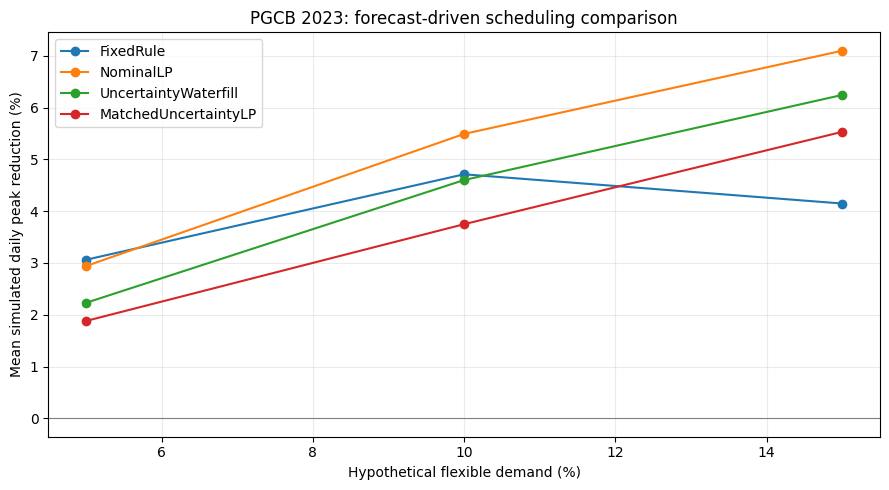

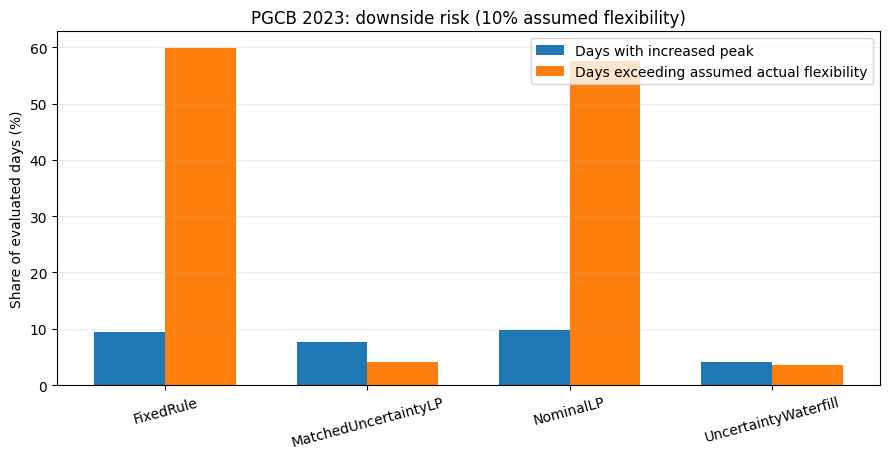

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
for name in ('FixedRule', 'NominalLP', 'UncertaintyWaterfill', 'MatchedUncertaintyLP'):
    curve = summary.loc[summary.method.eq(name)].sort_values('alpha')
    ax.plot(100 * curve.alpha, curve.mean_peak_reduction_pct, 'o-', label=name)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set(xlabel='Hypothetical flexible demand (%)',
       ylabel='Mean simulated daily peak reduction (%)',
       title='PGCB 2023: forecast-driven scheduling comparison')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / 'figure_2023_mean_peak_reduction.png', dpi=600)
plt.show()

focused = summary.loc[summary.alpha.eq(0.10) & summary.method.ne('NoAction')].copy()
labels = focused.method.to_list()
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9, 4.7))
width = 0.35
ax.bar(positions - width / 2, focused.worsened_days_pct, width,
       label='Days with increased peak')
ax.bar(positions + width / 2, focused.actual_cap_violation_days_pct, width,
       label='Days exceeding assumed actual flexibility')
ax.set_xticks(positions, labels, rotation=15)
ax.set(ylabel='Share of evaluated days (%)',
       title='PGCB 2023: downside risk (10% assumed flexibility)')
ax.legend()
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(OUT_DIR / 'figure_2023_downside_risk.png', dpi=600)
plt.show()

## 16. Inspect an example day and the worst outcomes

A time-series graph helps us understand *how* a peak changed, not just the final percentage. We visualize one fixed 2023 date if it is eligible, otherwise the first eligible case. We also save the lowest-scoring days for each method so the eventual paper can discuss failure cases without hiding them.

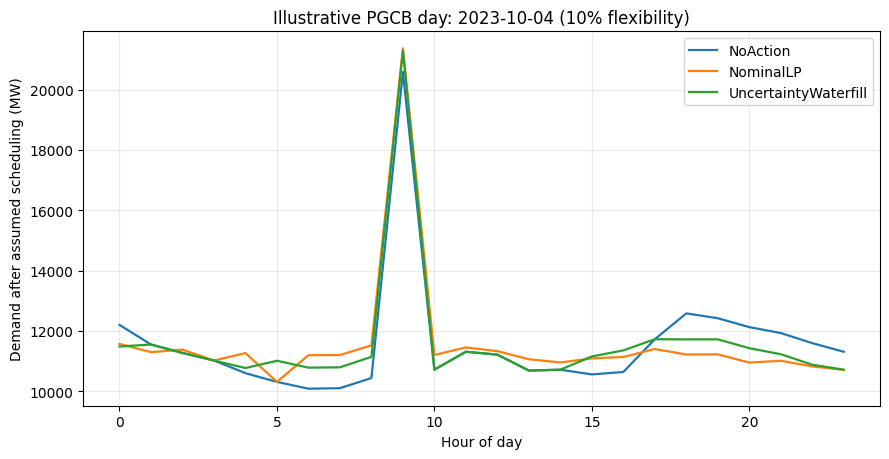

Five worst outcomes by method and flexibility saved.


In [ ]:
preferred_date = '2023-10-04'
example_date = preferred_date if preferred_date in daily['date'].unique() else daily['date'].iloc[0]
example = hourly_schedules.loc[
    hourly_schedules['date'].eq(example_date)
    & hourly_schedules['alpha'].eq(0.10)
]
fig, ax = plt.subplots(figsize=(9, 4.7))
for name in ('NoAction', 'NominalLP', 'UncertaintyWaterfill'):
    part = example.loc[example.method.eq(name)].sort_values('hour')
    ax.plot(part.hour, part.simulated_mw, label=name, linewidth=1.6)
ax.set(xlabel='Hour of day', ylabel='Demand after assumed scheduling (MW)',
       title=f'Illustrative PGCB day: {example_date} (10% flexibility)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / 'figure_2023_example_day.png', dpi=600)
plt.show()

worst_days = (daily.loc[daily.method.ne('NoAction')]
              .sort_values('peak_reduction_pct')
              .groupby(['method', 'alpha'], as_index=False).head(5))
worst_days.to_csv(OUT_DIR / 'phase3_worst_five_days_by_method.csv', index=False)
print('Five worst outcomes by method and flexibility saved.')

## 17. Export the reproducibility record and ZIP archive

The final cell writes the complete protocol—dataset checksum, fixed Ridge settings, error-envelope construction, optimizer definitions, software versions, and the limitations of these simulated results. This is helpful for GitHub, supervisory review, and later reproducibility checks. It also creates a ZIP archive of this run's tables, figures and model bundle without modifying earlier folders.

In [ ]:
protocol = {
    'research_title': 'An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids',
    'phase': 'Phase 3: uncertainty-aware candidate evaluation (novelty NOT established)',
    'run_id': RUN_ID,
    'dataset': {'source': 'UCI PGCB Hourly Generation Dataset (Bangladesh)',
                'doi': '10.24432/C59P6V', 'license': 'CC BY 4.0',
                'filename': DATA_PATH.name, 'sha256': SOURCE_SHA256},
    'forecast_model': {'name': 'Ridge', 'alpha': 100.0,
                       'feature_names': FEATURES, 'fitted_through': '2022-06-30',
                       '2023_mae_mw': evaluation_mae},
    'periods': {'forecast_train': '2015 to 2022-06-30',
                'error_calibration': '2022-07-01 to 2022-12-31',
                'exploratory_optimization_evaluation': '2023-01-01 to 2023-12-31'},
    'calibration': {'quantile': ERROR_QUANTILE, 'hour_specific_weight': HOUR_WEIGHT,
                    'global_underprediction_q_mw': global_under,
                    'global_overprediction_q_mw': global_over,
                    'empirical_2023_hourly_coverage_pct': coverage},
    'assumed_flexible_load_fractions': list(ALPHAS),
    'schedule_methods': list(SCHEDULERS),
    'adaptive_gate': 'forecast_peak_spread / (forecast_peak_spread + mean(under+over))',
    'energy_constraint': 'sum(hourly_shift_mw) = 0 on each 24h day (1h sampling)',
    'optimization_data_available_when_scheduling': 'forecast and 2022 calibration margins only',
    'n_evaluated_2023_days': len(cases),
    'time_audit': DATA_QUALITY,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'scipy': scipy.__version__,
                 'scikit_learn': sklearn.__version__},
    'limitations': [
        'Infeasible schedules with negative realized consumption are flagged, not projected or repaired with hindsight.',
        'Demand flexibility is hypothetical; consumer controllability is not observed in PGCB.',
        'Counterfactual shifted curves do not demonstrate actual avoided load shedding.',
        'Historical error margins have no formal temporal coverage guarantee.',
        'Even conservative schedules may exceed actual realized flexibility limits.',
        'Preprocessing and earlier 2023-2025 exploratory reviews mean that this is not a pristine final test.',
        'Water filling, optimization with uncertainty and demand shifting have prior research; novelty must be evaluated.',
        'No hourly dispatchable capacity, load-shifting costs, network constraints or customer preferences are available.',
        'Runtime comparisons depend on hardware, libraries, and solver settings.'
    ],
}
(OUT_DIR / 'phase3_protocol.json').write_text(json.dumps(protocol, indent=2))
archive_path = OUT_DIR / 'phase3_outputs.zip'
with zipfile.ZipFile(archive_path, mode='w', compression=zipfile.ZIP_DEFLATED) as archive:
    for item in sorted(OUT_DIR.iterdir()):
        if item.is_file() and item != archive_path:
            archive.write(item, arcname=item.name)
required = [
    'phase3_daily_results_2023.csv', 'phase3_hourly_schedules_2023.csv',
    'phase3_summary_2023.csv', 'phase3_paired_peak_comparisons_2023.csv',
    'error_margins_2022_H2.csv', 'phase3_protocol.json', 'phase3_outputs.zip',
]
assert all((OUT_DIR / name).exists() for name in required)
print('Phase 3 experiment complete.')
print('Exploratory evaluation days:', len(cases))
print('Results stored at:', OUT_DIR)
print('Research next step: assess novelty, revise with 2022-only development, and freeze a defensible later evaluation protocol.')

Phase 3 experiment complete.
Exploratory evaluation days: 274
Results stored at: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase3_20261107T085050Z_d0dbce
Research next step: assess novelty, revise with 2022-only development, and freeze a defensible later evaluation protocol.
